### **1. Importing Libraries**

In [1]:
# !pip install tweet-preprocessor

In [2]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
# import tensorflow as tf

import sys
sys.path.append('/opt/homebrew/lib/python3.11/site-packages')
import preprocessor as p  # tweet-preprocessor package

In [4]:
# import nltk
# from sklearn.feature_extraction.text import CountVectorizer
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.preprocessing import LabelBinarizer
# from nltk.corpus import stopwords
# from nltk.stem.porter import PorterStemmer
# from wordcloud import WordCloud,STOPWORDS
# from nltk.stem import WordNetLemmatizer
# from nltk.tokenize import word_tokenize,sent_tokenize
# from bs4 import BeautifulSoup
# import spacy
# import re,string,unicodedata
# from nltk.tokenize.toktok import ToktokTokenizer
# from nltk.stem import LancasterStemmer,WordNetLemmatizer
# from sklearn.naive_bayes import MultinomialNB
# from textblob import TextBlob
# from textblob import Word
# from sklearn.metrics import classification_report,confusion_matrix,accuracy_score
# from sklearn.model_selection import train_test_split
# import plotly

ModuleNotFoundError: No module named 'nltk'

In [3]:
# Load the 'comments' Parquet file
df_comments = pd.read_parquet('data/comments.parquet.brotli', engine='pyarrow')
df_comments.head()

,post_id,comment_id,comment_content,comment_score,comment_created_utc
0,1501ibb,js0zukm,Did you get a second opinion?,6894,2023-07-15 04:18:00
1,1501ibb,js1079r,On purpose?,15404,2023-07-15 04:21:36
2,1501ibb,js1269h,"""Why does this keep happening to me?! Second t...",11788,2023-07-15 04:41:47
3,1501ibb,js11llk,“Is it yours?”,24645,2023-07-15 04:35:52
4,1501ibb,js0yusy,Congrats! Whose is it?,8216,2023-07-15 04:07:51


In [4]:
df_comments.count()

post_id                983115
comment_id             983115
comment_content        983115
comment_score          983115
comment_created_utc    983115
dtype: int64

### **2. Loading Dataset**

In [5]:
#Dropping Empty and Duplicate Data

df_comments = df_comments.dropna()
df_comments = df_comments.drop_duplicates()
df_comments.count()

post_id                970664
comment_id             970664
comment_content        970664
comment_score          970664
comment_created_utc    970664
dtype: int64

### **3. Data Pre-processing**

#### **Data Cleaned to Normal Text and Empty & Duplicate Tweets are removed again**




In [6]:
def preprocess_comment_content(row):
    comment_content = row['comment_content']
    comment_content = p.clean(comment_content)
    return comment_content

In [7]:
df_comments['comment_content'] = df_comments.apply(preprocess_comment_content, axis=1)

In [8]:
df_comments.head()

,post_id,comment_id,comment_content,comment_score,comment_created_utc
0,1501ibb,js0zukm,Did you get a second opinion?,6894,2023-07-15 04:18:00
1,1501ibb,js1079r,On purpose?,15404,2023-07-15 04:21:36
2,1501ibb,js1269h,"""Why does this keep happening to me?! Second t...",11788,2023-07-15 04:41:47
3,1501ibb,js11llk,Is it yours?,24645,2023-07-15 04:35:52
4,1501ibb,js0yusy,Congrats! Whose is it?,8216,2023-07-15 04:07:51


In [9]:
df_comments = df_comments.dropna()
df_comments = df_comments.drop_duplicates()
df_comments.count()

post_id                970663
comment_id             970663
comment_content        970663
comment_score          970663
comment_created_utc    970663
dtype: int64

#### **Normal text preprocessing like**

1. Stopwords removal
2. Replace extra white spaces
3. Punctuation Removal
4. Lowercasing

In [13]:
# !pip install --upgrade gensim

In [10]:
from gensim.parsing.preprocessing import remove_stopwords

In [11]:
def stopword_removal(row):
    comment_content = row['comment_content']
    comment_content = remove_stopwords(comment_content)
    return comment_content

In [12]:
df_comments['comment_content'] = df_comments.apply(stopword_removal, axis=1)

In [13]:
df_comments['comment_content'] = df_comments['comment_content'].str.lower().str.replace('[^\w\s]',' ').str.replace('\s\s+', ' ')

### **4. Tokenization**


In [18]:
# nltk.download('punkt')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [15]:
import nltk

In [17]:
from nltk.tokenize import word_tokenize
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/allegrachen/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [18]:
from nltk.tokenize import word_tokenize
df_comments['comment_content'] = df_comments['comment_content'].apply(word_tokenize)

### **5. Stemming and Lemmatization**


In [19]:
from nltk.stem.porter import PorterStemmer
stemmer = PorterStemmer()
def stem_words(text):
    return " ".join([stemmer.stem(word) for word in text])
df_comments['comment_content'] = df_comments['comment_content'].apply(lambda text: stem_words(text))

### **6. Lexicon Based Sentiment Calculation**


In [21]:
from textblob import TextBlob

In [22]:
df_comments['polarity'] = df_comments['comment_content'].apply(lambda x: TextBlob(x).sentiment.polarity)
df_comments['subjectivity'] = df_comments['comment_content'].apply(lambda x: TextBlob(x).sentiment.subjectivity)

In [27]:
def getAnalysis(score):
   if score < 0:
    return '-1'
   elif score == 0:
     return '0'
   else:
     return '1'
df_comments['sentiment'] = df_comments['polarity'].apply(getAnalysis)

In [28]:
df_comments.head()

,post_id,comment_id,comment_content,comment_score,comment_created_utc,polarity,subjectivity,Analysis,sentiment
0,1501ibb,js0zukm,did second opinion ?,6894,2023-07-15 04:18:00,0.0,0.0,0,0
1,1501ibb,js1079r,on purpos ?,15404,2023-07-15 04:21:36,0.0,0.0,0,0
2,1501ibb,js1269h,`` whi happen me ? ! second time week ! '',11788,2023-07-15 04:41:47,0.0,0.0,0,0
3,1501ibb,js11llk,is your ?,24645,2023-07-15 04:35:52,0.0,0.0,0,0
4,1501ibb,js0yusy,congrat ! whose it ?,8216,2023-07-15 04:07:51,0.0,0.0,0,0


/var/folders/xs/8150jdld2zl47ndf914xvw840000gn/T/ipykernel_14495/2975785506.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.relplot(x='polarity', y='subjectivity',


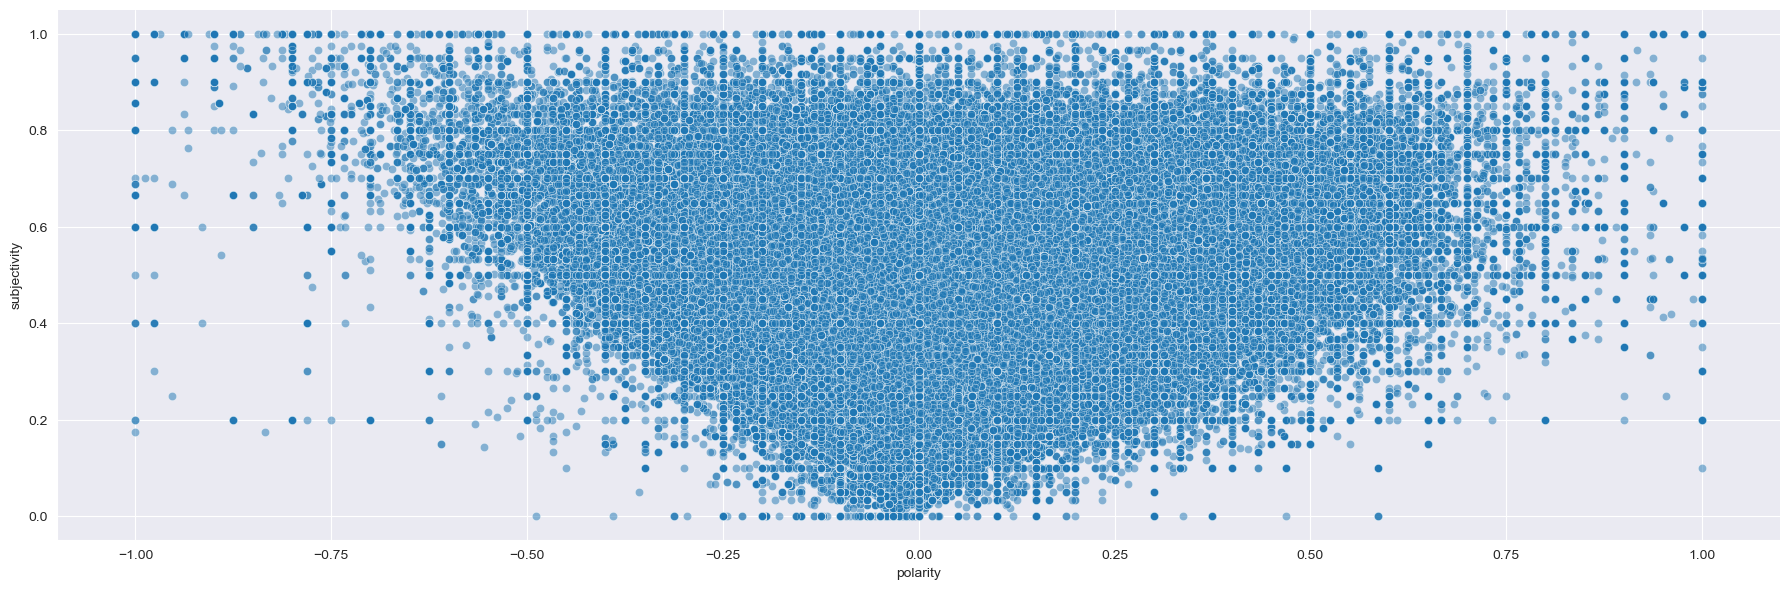

In [26]:
sns.set_style(style= 'darkgrid')
sns.relplot(x='polarity', y='subjectivity',
            sizes=(40, 400), alpha=.5, palette="mako",
            height=6, aspect = 3,data=df_comments)

In [30]:
df_lexicon_comment_sentiment = df_comments[['post_id', 'comment_id', 'sentiment']]
df_lexicon_comment_sentiment = df_lexicon_comment_sentiment.rename(columns={'sentiment': 'lexicon_sentiment'})

df_lexicon_comment_sentiment.to_csv('data/lexicon_comment_sentiment.csv')

In [32]:
df_selected_comments = pd.read_csv('data/selected_comments_with_RoBERTa.csv')
df_selected_comments.head()

,post_id,comment_id,comment_content,comment_score,comment_created_utc,length_category,sentiment,RoBERTa_sentiment
0,1gilleg,lv7vg3z,Reddit is like collectively climaxing.,4,2024-11-03 18:30:42,short,1.0,-1
1,1g8neev,lt1c2f6,Growing anti illegal immigrant policy.,1,2024-10-21 17:28:18,short,0.0,-1
2,1gfyg6n,lumbb5b,Fred Weasley is exactly my thought too.,10,2024-10-31 00:39:50,short,0.0,0
3,1573cx1,jt4kh7n,I shouldn't love this as much as I do lol.,2,2023-07-23 14:44:13,short,1.0,-1
4,151kc60,jsa6kfd,Oh fuck that’s worse then what I was thinking.,1,2023-07-17 04:49:32,short,-1.0,-1


In [73]:
df = pd.merge(left=df_selected_comments[['post_id', 'comment_id', 'sentiment']],
         right=df_lexicon_comment_sentiment,
         on=['post_id', 'comment_id'])

# df['sentiment'] = df['sentiment'].astype('int')

matches = df['sentiment'] == df['lexicon_sentiment'].astype('int')

print(np.mean(matches))

0.46540880503144655


#### **Word Cloud**

In [ ]:
from PIL import Image
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
import matplotlib.pyplot as plt

text = " ".join(review for review in df_comments.comment_content)
print ("There are {} words in the combination of all review.".format(len(text)))

In [ ]:
wordcl = WordCloud(background_color="white").generate(text)
plt.imshow(wordcl, interpolation='bilinear')
plt.axis('off')
plt.show()

In [ ]:
df_comments.head(20)

In [ ]:
df_comments.tail(20)

### **7. Word Embedding (Bag of Words)**

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
bow = CountVectorizer( min_df=2,max_features=100000)
bow.fit(df_comments['comment_content'])
comments_processed = bow.transform(df_comments['comment_content']).toarray()